# Small samples and noise (step 0.38)

The site will show every team's record in every situation: "Raiders, 2–0 in light rain". This notebook measures how much of a split like that is luck, in three ways:

1. **Shuffle test:** how many team splits look "significant" even when the situation labels are shuffled at random?
2. **Regression to the mean:** does a team's split in 2015–2019 repeat in 2021–2025?
3. **Shrinkage:** how far should a small-sample split be pulled back toward the team's normal record?

**Data:**
- Regular-season games from `team_games`.
- The shuffle test and shrinkage use the site's default range, the last three seasons (2023–2025): 51 games per team.
- The persistence check compares two five-season windows, 2015–2019 and 2021–2025. 2020 falls between them, which also keeps it out of the venue splits.
- Each split is a team's record in one situation value, from that team's games only. A team's own games are independent of each other.

**Win %** counts a tie as half a win. Fisher's test needs whole wins, so there a tie counts as not won. The 2023–2025 window has one tie.

In [1]:
import sys
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

from pipeline.analysis import (
    FIGURES_DIR,
    LAST_SEASON,
    N_RESAMPLES,
    SEED,
    SERIES,
    SURFACE,
    TEXT_SECONDARY,
    bh_adjust,
    chart_style,
    fisher_p_table,
    read_mart,
    regular_season,
    save_figure,
    win_score,
)

chart_style()
pd.set_option("display.width", 200)

SITE_RANGE = (LAST_SEASON - 2, LAST_SEASON)  # the site's default: the last three seasons
WINDOW_A, WINDOW_B = (2015, 2019), (2021, 2025)
N_SHUFFLES = 1000

situations = read_mart("situations").set_index("key")
# The 13 situations the analysis covered, as pre-registered. Step 0.39 added rest_advantage to the
# registry afterwards, and trimmed three of these from v1 (in_v1), which doesn't change the analysis.
PHASE3_SITUATIONS = ["venue", "roof", "surface", "temperature", "precipitation", "wind", "time_slot",
                     "primetime", "rest", "time_zone_travel", "body_clock", "opponent_type", "spread_role"]
situations = situations.loc[PHASE3_SITUATIONS]
team_games = regular_season(read_mart("team_games"), WINDOW_A[0], LAST_SEASON)
team_games["win"] = win_score(team_games["result"])  # 1, ½ for a tie, 0
team_games["won"] = (team_games["result"] == "win").astype(int)  # Fisher's test: a tie counts as not won
team_games["is_primetime"] = team_games["is_primetime"].map({True: "true", False: "false"})  # the registry's spelling
recent = team_games[team_games["season"].between(*SITE_RANGE)]
print(f"{SITE_RANGE[0]}–{SITE_RANGE[1]}: {len(recent):,} team-games, {recent.groupby('team').size().unique()} games per team, "
      f"{(recent['result'] == 'tie').sum() // 2} tie game(s)")

2023–2025: 1,632 team-games, [51] games per team, 1 tie game(s)


## The statistics, in plain English

**Multiple comparisons.** 32 teams × about 45 situation values gives roughly 1,400 splits. Even if none of them meant anything, testing each at the 5% level would flag dozens.

**Fisher's exact test.** With a sample as small as two games, the usual normal-curve formulas break down. Fisher's test treats a team's games as an urn of wins and losses. It then asks exactly how likely a split at least this lopsided would be if the bucket's games were a random draw from that urn. For the Raiders, 15–36 over 2023–2025, two random games are both wins 15/51 × 14/50 = 8.2% of the time.

**Permutation (shuffle) test.** Shuffle the situation labels among each team's own games.
- The team keeps its record and its number of rain games.
- Any real link between rain and winning is destroyed.

Count the "significant" splits, and repeat 1,000 times. The result is how many chance alone produces: the yardstick for the real count. Fisher's test is cautious with tiny samples, so the shuffle also shows its real false-alarm rate, rather than the nominal 5%.

**Regression to the mean.** An extreme result is part skill and part luck, and only the skill repeats. So the next sample usually lands closer to average. To measure it, a team's *own* split (its split minus the league's average split for that value) in 2015–2019 is correlated with the same split in 2021–2025. A correlation near zero means the split was mostly luck.

**Shrinkage (empirical Bayes).** The best estimate of a team's true record in a situation is a weighted average of two things:
- its record there, weighted by its n games;
- its overall record plus the league's average split for that value, weighted as if it were k games.

So the weight on the team's own split is n / (n + k). k is how many games of luck it takes to equal the real differences between teams:

k = (luck per game) / (real variation in the split)

The real variation is estimated from persistence. Luck in 2015–2019 and luck in 2021–2025 are unrelated, so whatever the two windows' splits share is real. Their covariance (the average of the product of the two splits) measures that shared part. When almost nothing repeats, k is large and a two-game record barely moves the estimate.

## The example: the Raiders, 2–0 in light rain

Among every 2–0 rain split of 2023–2025 (light or heavy), this is the one with the worst overall record: the most misleading-looking.

In [2]:
rain = recent[recent["precipitation_bucket"].isin(["light_rain", "heavy_rain"])]
rain_records = rain.groupby(["team", "precipitation_bucket"])["won"].agg(games="size", wins="sum").reset_index()
overall = recent.groupby("team").agg(all_games=("won", "size"), all_wins=("won", "sum"), all_win_pct=("win", "mean"))
two_and_oh = rain_records[(rain_records["games"] == 2) & (rain_records["wins"] == 2)].join(overall, on="team")
display(two_and_oh.sort_values("all_win_pct").round(3))

example = two_and_oh.sort_values("all_win_pct").iloc[0]
EXAMPLE_TEAM, EXAMPLE_VALUE = example["team"], example["precipitation_bucket"]
example_rain_games = rain[rain["team"] == EXAMPLE_TEAM]
luck_two_and_oh = example["all_wins"] / example["all_games"] * (example["all_wins"] - 1) / (example["all_games"] - 1)
example_p = fisher_p_table(int(example["all_games"]), int(example["all_wins"]))[2, 2]
print(f"{EXAMPLE_TEAM}: {example['all_wins']:.0f}–{example['all_games'] - example['all_wins']:.0f} over {SITE_RANGE[0]}–{SITE_RANGE[1]}, "
      f"2–0 in {EXAMPLE_VALUE.replace('_', ' ')} ({len(example_rain_games)} rain games in all)")
print(f"Chance that two random games of that season are both wins: {luck_two_and_oh:.1%}")
print(f"Fisher's exact p-value, 2–0 against the other games: {example_p:.3f}")

,team,precipitation_bucket,games,wins,all_games,all_wins,all_win_pct
32,LV,light_rain,2,2,51,15,0.294
26,KC,heavy_rain,2,2,51,32,0.627


LV: 15–36 over 2023–2025, 2–0 in light rain (2 rain games in all)
Chance that two random games of that season are both wins: 8.2%
Fisher's exact p-value, 2–0 against the other games: 0.082


## 1. How many splits look significant by chance?

Each team-and-situation pair becomes a *block*: the team's games that have a value for that situation, as value codes and won flags. `fisher_p_table` precomputes the p-value of every possible split of a block (any n games, any w wins), so a shuffle only has to count.

In [3]:
p_table = lru_cache(maxsize=None)(fisher_p_table)  # one table per (games, wins) total


def team_blocks(frame: pd.DataFrame) -> list[dict]:
    blocks = []
    for key, situation in situations.iterrows():
        values = situation["value_list"].split("|")
        code_of = {value: i for i, value in enumerate(values)}
        has_value = frame[frame[situation["column_name"]].notna()]
        for team, rows in has_value.groupby("team"):
            blocks.append(
                {"team": team, "situation": key, "values": values,
                 "codes": rows[situation["column_name"]].map(code_of).to_numpy(), "won": rows["won"].to_numpy(),
                 # Row positions per season and per venue, for the shuffles that keep those groups apart.
                 "season_groups": [np.flatnonzero(rows["season"].to_numpy() == s) for s in rows["season"].unique()],
                 "venue_groups": [np.flatnonzero(rows["venue"].to_numpy() == v) for v in rows["venue"].unique()]}
            )
    return blocks


def shuffle_within(codes: np.ndarray, groups: list, rng: np.random.Generator) -> np.ndarray:
    """Shuffle the labels inside each group only (e.g. within each season), never across groups."""
    shuffled_codes = codes.copy()
    for group in groups:
        shuffled_codes[group] = rng.permutation(codes[group])
    return shuffled_codes


def split_tests(block: dict, codes: np.ndarray) -> tuple:
    """Games, wins and Fisher p-value for each value the team played in."""
    n_values = len(block["values"])
    games = np.bincount(codes, minlength=n_values)
    wins = np.bincount(codes, weights=block["won"], minlength=n_values).astype(int)
    p = p_table(len(codes), int(block["won"].sum()))[games, wins]
    played = np.flatnonzero(games > 0)
    return played, games[played], wins[played], p[played]


blocks = team_blocks(recent)
real_rows = []
for block in blocks:
    played, games, wins, p = split_tests(block, block["codes"])
    real_rows += [(block["team"], block["situation"], block["values"][i], g, w, pv) for i, g, w, pv in zip(played, games, wins, p)]
real = pd.DataFrame(real_rows, columns=["team", "situation", "value", "games", "wins", "p"])
real["p_adj"] = bh_adjust(real["p"])

keys = list(situations.index)
# Three shuffles, each with its own random stream: across all of a team's games (the main test), only within each
# season, and only within its home games and within its away games (the last two test an explanation below).
NULLS = {"plain": None, "within season": "season_groups", "within home/away": "venue_groups"}
streams = {name: np.random.default_rng(SEED + i) for i, name in enumerate(NULLS)}
null_counts = {name: np.zeros((N_SHUFFLES, len(keys)), dtype=int) for name in NULLS}  # "significant" splits per shuffle and situation
for s in range(N_SHUFFLES):
    for block in blocks:
        i = keys.index(block["situation"])
        for name, groups in NULLS.items():
            rng = streams[name]
            codes = rng.permutation(block["codes"]) if groups is None else shuffle_within(block["codes"], block[groups], rng)
            _, _, _, p = split_tests(block, codes)
            null_counts[name][s, i] += (p < 0.05).sum()
shuffled = null_counts["plain"]

real_counts = real[real["p"] < 0.05].groupby("situation").size().reindex(keys, fill_value=0)
print(f"{len(real):,} team splits; {real_counts.sum()} have p < 0.05; {(real['p_adj'] <= 0.05).sum()} survive Benjamini–Hochberg")
print(f"Shuffled labels: {shuffled.sum(axis=1).mean():.1f} 'significant' splits on average "
      f"(nominal 5% would be {0.05 * len(real):.0f}; Fisher's test is cautious with tiny samples)")

1,419 team splits; 46 have p < 0.05; 0 survive Benjamini–Hochberg
Shuffled labels: 33.5 'significant' splits on average (nominal 5% would be 71; Fisher's test is cautious with tiny samples)


### Where the real count falls

For each situation, and for the 12 together (spread role aside), the table places the real count in the shuffled distribution:
- **Percentile:** the share of shuffles with fewer "significant" splits, plus half of those with exactly as many (counts are whole numbers, so ties are common).
- **Lower and upper tail:** the share of shuffles with at most, and at least, as many as the real data.

The normal range is the middle 95% of shuffles: both tails at 2.5% or more.

In [4]:
def percentile_of(value: float, draws: np.ndarray) -> float:
    """Where value falls among draws: the share below it, plus half the share equal to it."""
    return (draws < value).mean() + 0.5 * (draws == value).mean()


def ordinal(share: float) -> str:
    n = round(100 * share)
    return f"{n}{'th' if 10 <= n % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(n % 10, 'th')}"


by_situation = pd.DataFrame(
    {
        "splits": real.groupby("situation").size().reindex(keys),
        "real p < 0.05": real_counts,
        "shuffled mean": shuffled.mean(axis=0),
        "percentile of real": [percentile_of(real_counts.iloc[i], shuffled[:, i]) for i in range(len(keys))],
        "lower tail": [(shuffled[:, i] <= real_counts.iloc[i]).mean() for i in range(len(keys))],
        "upper tail": [(shuffled[:, i] >= real_counts.iloc[i]).mean() for i in range(len(keys))],
        "mean, within season": null_counts["within season"].mean(axis=0),
        "mean, within home/away": null_counts["within home/away"].mean(axis=0),
    },
    index=keys,
)
display(by_situation.round(3))

others = [key for key in keys if key != "spread_role"]
other_columns = [keys.index(key) for key in others]
real_excluding = int(real_counts.drop("spread_role").sum())
excluding = {name: counts[:, other_columns].sum(axis=1) for name, counts in null_counts.items()}
shuffled_excluding = excluding["plain"]
real_percentile = percentile_of(real_excluding, shuffled_excluding)
lower_tail = (shuffled_excluding <= real_excluding).mean()
normal_low, normal_high = np.percentile(shuffled_excluding, [2.5, 97.5])
print(f"Spread role: {real_counts['spread_role']} real against {shuffled[:, keys.index('spread_role')].mean():.1f} shuffled: "
      "favourites win more, which is team quality, not a team-specific quirk.")
print(f"The other {len(others)} situations: {real_excluding} real against {shuffled_excluding.mean():.1f} shuffled on average "
      f"(middle 95% of shuffles: {normal_low:.0f} to {normal_high:.0f}). The real count is at the {ordinal(real_percentile)} percentile: "
      f"{(shuffled_excluding < real_excluding).mean():.1%} of shuffles flag fewer, {lower_tail:.1%} as many or fewer.")
for name in ["within season", "within home/away"]:
    print(f"Shuffling {name}: {excluding[name].mean():.1f} on average; {(excluding[name] <= real_excluding).mean():.1%} as many as the real count or fewer.")

,splits,real p < 0.05,shuffled mean,percentile of real,lower tail,upper tail,"mean, within season","mean, within home/away"
venue,86,3,2.294,0.666,0.733,0.401,2.143,3.000
roof,112,0,2.522,0.062,0.123,1.000,2.093,2.271
surface,64,0,2.426,0.149,0.298,1.000,2.330,2.318
temperature,115,1,2.332,0.236,0.345,0.872,2.552,2.572
precipitation,100,1,1.314,0.479,0.627,0.669,1.618,1.597
wind,94,6,2.000,0.977,0.989,0.034,2.062,2.148
time_slot,204,3,3.700,0.406,0.510,0.697,3.684,3.628
primetime,64,2,1.874,0.570,0.761,0.622,1.728,1.766
rest,126,1,2.437,0.207,0.313,0.899,2.179,2.565
time_zone_travel,95,0,2.301,0.091,0.182,1.000,2.071,2.072


Spread role: 26 real against 4.0 shuffled: favourites win more, which is team quality, not a team-specific quirk.
The other 12 situations: 20 real against 29.5 shuffled on average (middle 95% of shuffles: 18 to 43). The real count is at the 7th percentile: 5.7% of shuffles flag fewer, 7.7% as many or fewer.
Shuffling within season: 28.2 on average; 10.2% as many as the real count or fewer.
Shuffling within home/away: 30.0 on average; 4.6% as many as the real count or fewer.


The real count sits in the normal range but toward its low end: real schedules produce slightly *fewer* "significant" splits than shuffled labels.

**The obvious explanation is schedule balance, and it fails.** Real schedules are balanced in ways a random shuffle isn't:
- each season has its own home games, divisional games and time slots;
- a team's quality changes from season to season.

So a plain shuffle can bunch one team's labels into its best or worst season, or mostly into its home games, and make lopsided splits more often. The two extra shuffles test this: one shuffles labels only within each season, the other only within home games and within away games. If balance were the reason, their averages would drop to the real count. They barely move (see above), so balance doesn't explain it.

Per situation, every real count is inside its own normal range: even the situations with zero "significant" splits get zero often enough by chance. **The low total is most likely chance**, and the finding stands as *no more significant splits than noise*.

At the other end, one situation's count is unusually high. The cell below checks whether that is more than multiple comparisons.

In [5]:
upper = by_situation.loc[others, "upper tail"]
highest, highest_p = upper.idxmin(), upper.min()
formula = 1 - (1 - highest_p) ** len(others)
# Directly in the shuffles: how often is at least one situation at least that far into its own upper tail?
tails = np.column_stack([(shuffled[:, j][None, :] >= shuffled[:, j][:, None]).mean(axis=1) for j in other_columns])
direct = (tails.min(axis=1) <= highest_p).mean()
print(f"Most unusual: {situations.loc[highest, 'label']}, {real_counts[highest]} real against {shuffled[:, keys.index(highest)].mean():.1f} "
      f"shuffled; {highest_p:.1%} of shuffles reach it.")
print(f"Chance that at least one of {len(others)} situations lands that far out by luck: 1 − (1 − {highest_p:.3f})^{len(others)} = {formula:.0%} "
      f"(if they were independent); counted directly in the shuffles, {direct:.0%}.")
assert by_situation.loc[others, ["lower tail", "upper tail"]].min().min() >= 0.025  # every situation is within its normal range
assert normal_low <= real_excluding <= normal_high and formula > 0.2
assert all(excluding[name].mean() - real_excluding > 5 for name in ["within season", "within home/away"])  # balance doesn't explain it

Most unusual: Wind, 6 real against 2.0 shuffled; 3.4% of shuffles reach it.
Chance that at least one of 12 situations lands that far out by luck: 1 − (1 − 0.034)^12 = 34% (if they were independent); counted directly in the shuffles, 24%.


The two-game splits make the same point more simply. For each two-game split the site would show, chance gives the probability of 2–0 from the team's own record. Summing those probabilities gives the number of 2–0 records that luck alone predicts.

In [6]:
block_totals = {(b["team"], b["situation"]): (len(b["codes"]), int(b["won"].sum())) for b in blocks}
two_game = real[real["games"] == 2].copy()
totals = two_game.apply(lambda r: block_totals[(r["team"], r["situation"])], axis=1)
two_game["chance_of_2_0"] = [w / n * (w - 1) / (n - 1) for n, w in totals]
expected_two_and_oh, actual_two_and_oh = two_game["chance_of_2_0"].sum(), int((two_game["wins"] == 2).sum())
print(f"{len(two_game)} two-game splits: luck predicts {expected_two_and_oh:.1f} to be 2–0; there are {actual_two_and_oh}")

90 two-game splits: luck predicts 20.2 to be 2–0; there are 20


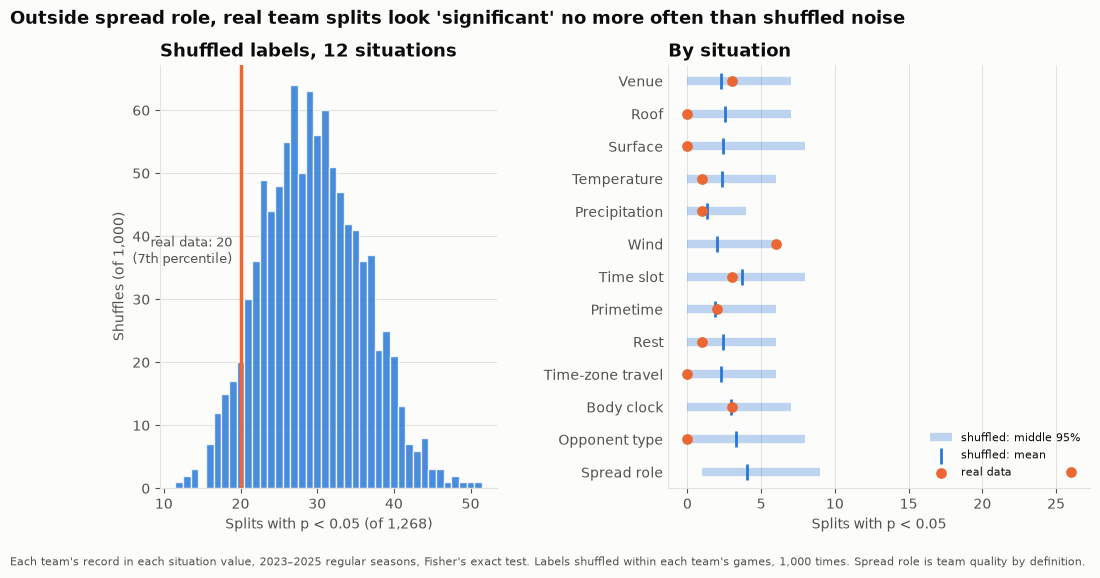

In [7]:
fig, (ax_hist, ax_sit) = plt.subplots(1, 2, figsize=(12, 5.5), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.45})
bins = np.arange(shuffled_excluding.min(), shuffled_excluding.max() + 2) - 0.5
ax_hist.hist(shuffled_excluding, bins=bins, color=SERIES[0], alpha=0.85, edgecolor=SURFACE, linewidth=1)
ax_hist.axvline(real_excluding, color=SERIES[1], linewidth=2.5)
ax_hist.annotate(f"real data: {real_excluding}\n({ordinal(real_percentile)} percentile)", (real_excluding, ax_hist.get_ylim()[1] * 0.6),
                 xytext=(-6, 0), textcoords="offset points",
                 color=TEXT_SECONDARY, fontsize=9, ha="right", va="top")
ax_hist.set_title("Shuffled labels, 12 situations")
ax_hist.set_xlabel(f"Splits with p < 0.05 (of {len(real[real['situation'] != 'spread_role']):,})")
ax_hist.set_ylabel(f"Shuffles (of {N_SHUFFLES:,})")

labels = situations["label"].reindex(keys)
y = np.arange(len(keys))
low, high = np.percentile(shuffled, 2.5, axis=0), np.percentile(shuffled, 97.5, axis=0)
ax_sit.hlines(y, low, high, color=SERIES[0], linewidth=6, alpha=0.3, label="shuffled: middle 95%")
ax_sit.scatter(shuffled.mean(axis=0), y, marker="|", s=120, color=SERIES[0], label="shuffled: mean")
ax_sit.scatter(real_counts, y, s=45, color=SERIES[1], zorder=3, label="real data")
ax_sit.set_yticks(y, labels)
ax_sit.set_ylim(len(keys) - 0.5, -0.5)
ax_sit.set_xlabel("Splits with p < 0.05")
ax_sit.set_title("By situation")
ax_sit.grid(axis="x", visible=True)
ax_sit.grid(axis="y", visible=False)
ax_sit.tick_params(axis="y", length=0)
ax_sit.legend(loc="lower right", fontsize=8)
fig.suptitle("Outside spread role, real team splits look 'significant' no more often than shuffled noise", x=0.0, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.0, -0.03, f"Each team's record in each situation value, {SITE_RANGE[0]}–{SITE_RANGE[1]} regular seasons, Fisher's exact test. "
         f"Labels shuffled within each team's games, {N_SHUFFLES:,} times. Spread role is team quality by definition.",
         fontsize=8, color=TEXT_SECONDARY)
save_figure(fig, "shuffle_significant_splits")
plt.show()

## 2. Do team splits repeat? Regression to the mean

For each window, `split_effects` computes three numbers for every team and situation value:
- the **split**: the team's win % in the value minus its win % in all its games;
- the **league split**: the average of all teams' splits for that value, weighted by games;
- the **own split**: the split minus the league split, i.e. what's particular to the team.

Then the own splits of 2015–2019 are paired with those of 2021–2025. Only pairs with at least 5 games in each window count, so the 1- and 2-game splits don't swamp the picture.

`luck_var` is the variance a split would have if the label didn't matter (the shuffle's variance, from sampling without replacement). Shrinkage uses it below.

In [8]:
def split_effects(frame: pd.DataFrame, registry: pd.DataFrame | None = None) -> pd.DataFrame:
    """Each team's split in every value of the registry's situations (default: the 13 pre-registered ones)."""
    registry = situations if registry is None else registry
    team = frame.groupby("team")["win"].agg(team_win_pct="mean", team_var=lambda w: w.var(ddof=0), team_games="size")
    parts = []
    for key, situation in registry.iterrows():
        column = situation["column_name"]
        split = frame[frame[column].notna()].groupby(["team", column])["win"].agg(games="size", win_pct="mean").reset_index()
        parts.append(split.rename(columns={column: "value"}).assign(situation=key))
    effects = pd.concat(parts, ignore_index=True).join(team, on="team")
    effects["split"] = effects["win_pct"] - effects["team_win_pct"]
    value = [effects["situation"], effects["value"]]
    effects["league_split"] = (effects["split"] * effects["games"]).groupby(value).transform("sum") / effects["games"].groupby(value).transform("sum")
    effects["own_split"] = effects["split"] - effects["league_split"]
    n, total = effects["games"], effects["team_games"]
    effects["luck_var"] = effects["team_var"] * (1 / n - 1 / total) * total / (total - 1)
    return effects


window_a = split_effects(team_games[team_games["season"].between(*WINDOW_A)])
window_b = split_effects(team_games[team_games["season"].between(*WINDOW_B)])
pairs = window_a.merge(window_b, on=["situation", "value", "team"], suffixes=("_a", "_b"))
pairs = pairs[(pairs["games_a"] >= 5) & (pairs["games_b"] >= 5)]


def team_bootstrap(frame: pd.DataFrame, statistic, n_resamples: int = N_RESAMPLES, seed: int = SEED) -> np.ndarray:
    """statistic(frame) on resamples of whole teams, drawn with replacement; each keeps all its rows."""
    rng = np.random.default_rng(seed)
    rows_of = {team: np.flatnonzero(frame["team"].to_numpy() == team) for team in frame["team"].unique()}
    teams = list(rows_of)
    return np.array([statistic(frame.iloc[np.concatenate([rows_of[t] for t in rng.choice(teams, len(teams))])]) for _ in range(n_resamples)])


def persistence(frame: pd.DataFrame) -> float:
    return float(np.corrcoef(frame["own_split_a"], frame["own_split_b"])[0, 1])


rows = []
for key in keys:
    data = pairs[pairs["situation"] == key]
    low, high = np.percentile(team_bootstrap(data, persistence), [2.5, 97.5])
    rows.append({"situation": situations.loc[key, "label"], "pairs": len(data), "r": persistence(data), "95% CI low": low, "95% CI high": high,
                 "repeating variance": float((data["own_split_a"] * data["own_split_b"]).mean())})
reliability = pd.DataFrame(rows, index=keys)
pooled_r = persistence(pairs)
pooled_low, pooled_high = np.percentile(team_bootstrap(pairs, persistence), [2.5, 97.5])
print(f"All {len(pairs):,} pairs: r = {pooled_r:.2f} [{pooled_low:.2f}, {pooled_high:.2f}]")
reliability.round(3)

All 1,083 pairs: r = 0.11 [0.02, 0.20]


,situation,pairs,r,95% CI low,95% CI high,repeating variance
venue,Venue,65,0.406,0.086,0.619,0.001
roof,Roof,65,0.138,-0.179,0.419,0.001
surface,Surface,64,0.035,-0.286,0.384,0.001
temperature,Temperature,87,0.021,-0.211,0.262,0.000
precipitation,Precipitation,51,0.168,-0.381,0.556,0.002
wind,Wind,80,0.110,-0.127,0.305,0.002
time_slot,Time slot,108,0.058,-0.200,0.327,0.001
primetime,Primetime,63,0.215,-0.105,0.527,0.001
rest,Rest,106,0.077,-0.171,0.314,0.002
time_zone_travel,Time-zone travel,75,0.181,-0.061,0.420,0.001


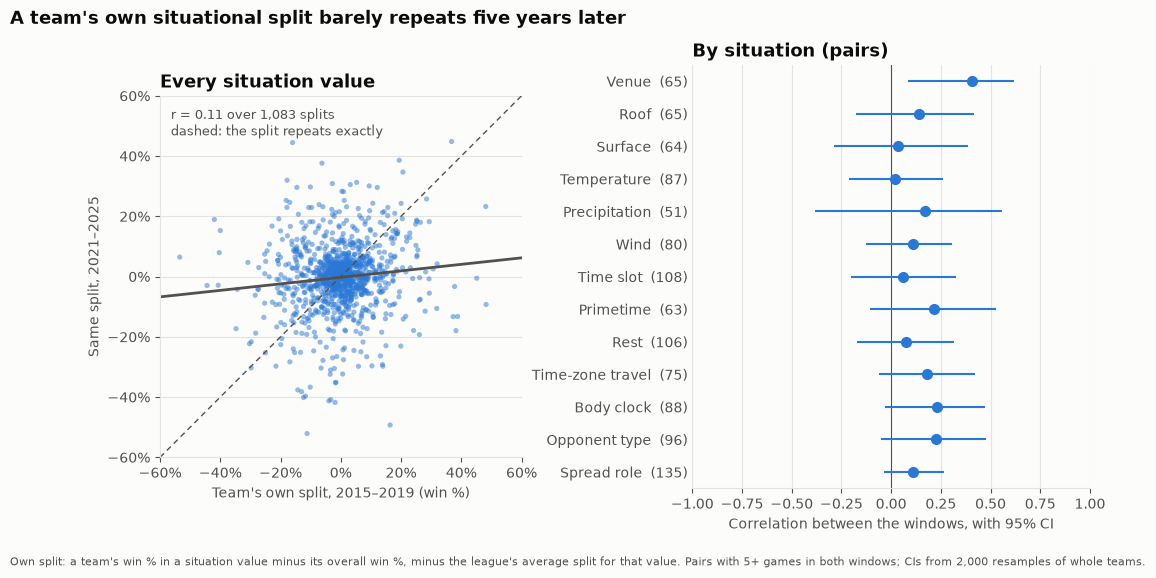

In [9]:
fig, (ax_scatter, ax_r) = plt.subplots(1, 2, figsize=(12, 5.5), gridspec_kw={"width_ratios": [1, 1.1], "wspace": 0.45})
limit = 0.6
ax_scatter.plot([-limit, limit], [-limit, limit], color=TEXT_SECONDARY, linewidth=1, linestyle=(0, (4, 3)))
ax_scatter.scatter(pairs["own_split_a"], pairs["own_split_b"], s=14, color=SERIES[0], alpha=0.5, edgecolor="none")
slope, intercept = np.polyfit(pairs["own_split_a"], pairs["own_split_b"], 1)
ax_scatter.plot([-limit, limit], [intercept - slope * limit, intercept + slope * limit], color=TEXT_SECONDARY, linewidth=2)
ax_scatter.text(0.03, 0.97, f"r = {pooled_r:.2f} over {len(pairs):,} splits\ndashed: the split repeats exactly", transform=ax_scatter.transAxes,
                va="top", fontsize=9, color=TEXT_SECONDARY)
ax_scatter.set_xlim(-limit, limit)
ax_scatter.set_ylim(-limit, limit)
ax_scatter.set_aspect("equal")
ax_scatter.xaxis.set_major_formatter(PercentFormatter(1.0))
ax_scatter.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_scatter.set_xlabel(f"Team's own split, {WINDOW_A[0]}–{WINDOW_A[1]} (win %)")
ax_scatter.set_ylabel(f"Same split, {WINDOW_B[0]}–{WINDOW_B[1]}")
ax_scatter.set_title("Every situation value")

y = np.arange(len(keys))
ax_r.axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax_r.errorbar(reliability["r"], y, xerr=[reliability["r"] - reliability["95% CI low"], reliability["95% CI high"] - reliability["r"]],
              fmt="o", color=SERIES[0], markersize=7, elinewidth=1.5, capsize=0)
ax_r.set_yticks(y, [f"{situations.loc[k, 'label']}  ({reliability.loc[k, 'pairs']})" for k in keys])
ax_r.set_ylim(len(keys) - 0.5, -0.5)
ax_r.set_xlim(-1, 1)
ax_r.set_xlabel("Correlation between the windows, with 95% CI")
ax_r.set_title("By situation (pairs)")
ax_r.grid(axis="x", visible=True)
ax_r.grid(axis="y", visible=False)
ax_r.tick_params(axis="y", length=0)
fig.suptitle("A team's own situational split barely repeats five years later", x=0.0, ha="left", fontsize=13, fontweight="bold")
fig.text(0.0, -0.03, f"Own split: a team's win % in a situation value minus its overall win %, minus the league's average split for that value. "
         f"Pairs with 5+ games in both windows; CIs from {N_RESAMPLES:,} resamples of whole teams.", fontsize=8, color=TEXT_SECONDARY)
save_figure(fig, "split_half_reliability")
plt.show()

## 3. Shrinkage

For each situation:
- **Real variation:** the variance that repeats across the two windows, floored at zero.
- **Luck per game:** the average variance of one team's results (about p × (1 − p) for a team with win rate p).
- **k** = luck per game / real variation. It's infinite when nothing repeats: the split is then all luck, and the estimate is the team's record plus the league's split.

Each 2023–2025 split is then pulled toward the team's overall win % plus the league split, keeping a weight of n / (n + k) on the team's own split.

For comparison, the table also shows the variance beyond luck within 2023–2025 alone. That's the same idea estimated from three seasons only, and it is noisier.

In [10]:
recent_effects = split_effects(recent)
luck_per_game = recent_effects.drop_duplicates("team")["team_var"].mean()
beyond_luck = recent_effects.assign(excess=recent_effects["own_split"] ** 2 - recent_effects["luck_var"]).groupby("situation")["excess"].mean()
shrinkage = pd.DataFrame(
    {
        "real variation (repeats)": reliability["repeating variance"].clip(lower=0),
        f"beyond luck, {SITE_RANGE[0]}–{SITE_RANGE[1]} alone": beyond_luck.reindex(keys).clip(lower=0),
    },
    index=keys,
)
with np.errstate(divide="ignore"):
    shrinkage["k (games)"] = luck_per_game / shrinkage["real variation (repeats)"]
shrinkage["weight on a 2-game split"] = 2 / (2 + shrinkage["k (games)"])
shrinkage["weight on a 25-game split"] = 25 / (25 + shrinkage["k (games)"])
print(f"Luck per game: {luck_per_game:.3f}")
display(shrinkage.round(4))

recent_effects["k"] = recent_effects["situation"].map(shrinkage["k (games)"])
recent_effects["weight"] = recent_effects["games"] / (recent_effects["games"] + recent_effects["k"])
recent_effects["shrunk"] = recent_effects["team_win_pct"] + recent_effects["league_split"] + recent_effects["weight"] * recent_effects["own_split"]
example_row = recent_effects[(recent_effects["team"] == EXAMPLE_TEAM) & (recent_effects["value"] == EXAMPLE_VALUE)].iloc[0]
print(f"{EXAMPLE_TEAM} in {EXAMPLE_VALUE.replace('_', ' ')}: raw {example_row['win_pct']:.0%} over {example_row['games']:.0f} games; "
      f"overall {example_row['team_win_pct']:.1%}; league split {example_row['league_split']:+.1%}; k = {example_row['k']:.0f}; "
      f"weight {example_row['weight']:.1%}; shrunk {example_row['shrunk']:.1%}")

Luck per game: 0.231


,real variation (repeats),"beyond luck, 2023–2025 alone",k (games),weight on a 2-game split,weight on a 25-game split
venue,0.0010,0.0000,220.9002,0.0090,0.1017
roof,0.0014,0.0000,169.8518,0.0116,0.1283
surface,0.0005,0.0000,446.9856,0.0045,0.0530
temperature,0.0003,0.0000,666.0119,0.0030,0.0362
precipitation,0.0019,0.0005,119.6190,0.0164,0.1729
wind,0.0016,0.0073,140.7096,0.0140,0.1509
time_slot,0.0010,0.0039,220.6967,0.0090,0.1018
primetime,0.0014,0.0072,164.7507,0.0120,0.1318
rest,0.0018,0.0000,128.5733,0.0153,0.1628
time_zone_travel,0.0014,0.0000,159.7608,0.0124,0.1353


LV in light rain: raw 100% over 2 games; overall 29.4%; league split -0.9%; k = 120; weight 1.6%; shrunk 29.6%


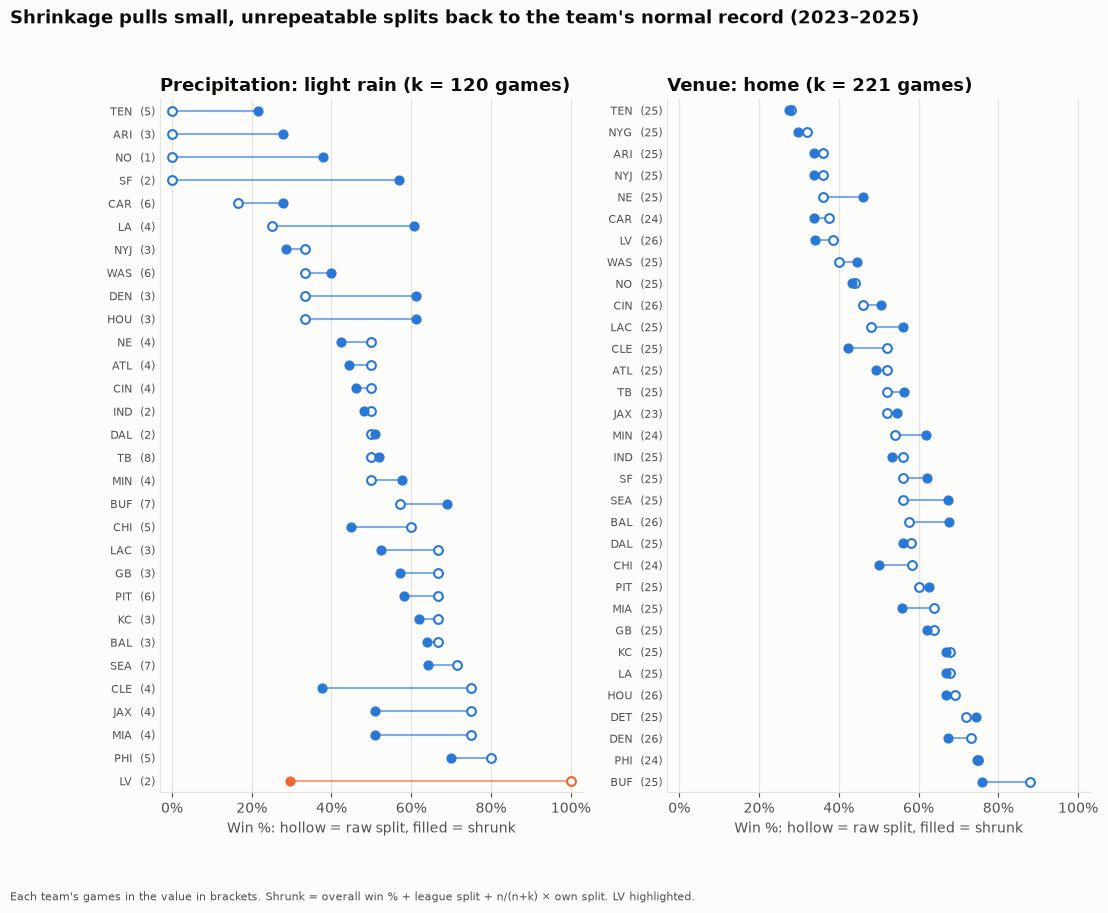

In [11]:
panels = [("precipitation", EXAMPLE_VALUE), ("venue", "home")]
fig, axes = plt.subplots(1, 2, figsize=(12, 9), sharex=True)
for ax, (key, value) in zip(axes, panels):
    data = recent_effects[(recent_effects["situation"] == key) & (recent_effects["value"] == value)].sort_values(["win_pct", "shrunk"])
    y = np.arange(len(data))
    is_example = (data["team"] == EXAMPLE_TEAM).to_numpy() & (key == "precipitation")
    for yi, (_, row), highlight in zip(y, data.iterrows(), is_example):
        color = SERIES[1] if highlight else SERIES[0]
        ax.plot([row["win_pct"], row["shrunk"]], [yi, yi], color=color, linewidth=1.5, alpha=0.6)
        ax.scatter(row["win_pct"], yi, s=40, facecolor=SURFACE, edgecolor=color, linewidth=1.5, zorder=3)
        ax.scatter(row["shrunk"], yi, s=40, color=color, zorder=3)
    ax.set_yticks(y, [f"{t}  ({n:.0f})" for t, n in zip(data["team"], data["games"])], fontsize=8)
    ax.set_ylim(len(data) - 0.5, -0.5)
    k_value = shrinkage.loc[key, "k (games)"]
    ax.set_title(f"{situations.loc[key, 'label']}: {value.replace('_', ' ')} (k = {'∞' if np.isinf(k_value) else f'{k_value:.0f}'} games)")
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("Win %: hollow = raw split, filled = shrunk")
    ax.grid(axis="x", visible=True)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
axes[0].set_xlim(-0.03, 1.03)
fig.suptitle(f"Shrinkage pulls small, unrepeatable splits back to the team's normal record ({SITE_RANGE[0]}–{SITE_RANGE[1]})",
             x=0.0, ha="left", fontsize=13, fontweight="bold")
fig.text(0.0, -0.01, f"Each team's games in the value in brackets. Shrunk = overall win % + league split + n/(n+k) × own split. "
         f"{EXAMPLE_TEAM} highlighted.", fontsize=8, color=TEXT_SECONDARY)
save_figure(fig, "raw_vs_shrunk")
plt.show()

## Why 2–0 in the rain means little

This is the plan's Done-when check, with the numbers computed above.

In [12]:
precipitation = reliability.loc["precipitation"]
assert example["games"] == 2 and example["wins"] == 2 and example_p > 0.05
assert abs(expected_two_and_oh - actual_two_and_oh) <= 3  # 2–0 records occur about as often as luck predicts
assert normal_low <= real_excluding <= normal_high  # outside spread role, within the normal range of noise
assert precipitation["95% CI low"] < 0 < precipitation["95% CI high"]  # rain splits don't measurably repeat
assert example_row["shrunk"] < example_row["team_win_pct"] + 0.1  # the shrunk estimate stays near the team's normal record
k_text = "infinite" if np.isinf(example_row["k"]) else f"about {example_row['k']:.0f} games"
display(Markdown(
    f"**{EXAMPLE_TEAM} went 2–0 in {EXAMPLE_VALUE.replace('_', ' ')} over {SITE_RANGE[0]}–{SITE_RANGE[1]}, while winning "
    f"{example['all_wins']:.0f} of {example['all_games']:.0f} games ({example['all_win_pct']:.0%}).** That record says almost nothing:\n\n"
    f"1. **Luck explains it.** Two random games from that stretch would both be wins {luck_two_and_oh:.0%} of the time. Across all "
    f"{len(two_game)} two-game splits the site would show, luck alone predicts {expected_two_and_oh:.0f} records of 2–0, and there are "
    f"{actual_two_and_oh}.\n"
    f"2. **It isn't significant, and neither are most splits.** Fisher's exact p-value for 2–0 against the other games is {example_p:.2f}. "
    f"Among {len(real):,} team splits, outside spread role (team quality by definition) the real data flag {real_excluding} as "
    f"'significant', against {shuffled_excluding.mean():.0f} on average with shuffled labels: no more than noise, at the low end of its "
    f"normal range ({ordinal(real_percentile)} percentile). Shuffles that keep each season's, or each home/away set's, games together "
    f"don't close that gap, so it isn't schedule balance; it's most likely chance. None of the {len(real):,} splits survive the "
    f"Benjamini–Hochberg correction.\n"
    f"3. **Rain splits don't measurably repeat.** A team's own precipitation split in {WINDOW_A[0]}–{WINDOW_A[1]} correlates "
    f"r = {precipitation['r']:.2f} [{precipitation['95% CI low']:.2f}, {precipitation['95% CI high']:.2f}] with the same split in "
    f"{WINDOW_B[0]}–{WINDOW_B[1]}. Across every situation, splits repeat only weakly (r = {pooled_r:.2f}).\n"
    f"4. **Shrunk, it's their normal record.** k for precipitation is {k_text}, so two games get a weight of "
    f"{example_row['weight']:.0%}. The best estimate of their win % in light rain is {example_row['shrunk']:.0%}: their overall "
    f"{example_row['team_win_pct']:.0%} plus the league's light-rain split ({example_row['league_split']:+.0%}), not 100%."
))

**LV went 2–0 in light rain over 2023–2025, while winning 15 of 51 games (29%).** That record says almost nothing:

1. **Luck explains it.** Two random games from that stretch would both be wins 8% of the time. Across all 90 two-game splits the site would show, luck alone predicts 20 records of 2–0, and there are 20.
2. **It isn't significant, and neither are most splits.** Fisher's exact p-value for 2–0 against the other games is 0.08. Among 1,419 team splits, outside spread role (team quality by definition) the real data flag 20 as 'significant', against 29 on average with shuffled labels: no more than noise, at the low end of its normal range (7th percentile). Shuffles that keep each season's, or each home/away set's, games together don't close that gap, so it isn't schedule balance; it's most likely chance. None of the 1,419 splits survive the Benjamini–Hochberg correction.
3. **Rain splits don't measurably repeat.** A team's own precipitation split in 2015–2019 correlates r = 0.17 [-0.38, 0.56] with the same split in 2021–2025. Across every situation, splits repeat only weakly (r = 0.11).
4. **Shrunk, it's their normal record.** k for precipitation is about 120 games, so two games get a weight of 2%. The best estimate of their win % in light rain is 30%: their overall 29% plus the league's light-rain split (-1%), not 100%.

## Caveats

- **Fisher's test ignores the opponent.** It treats a team's games as interchangeable, but the rain games might have come against weak or strong opponents. The shuffle shares that blind spot, so the comparison is still fair.
- **Two-valued situations count twice.** Surface (grass/turf), primetime (yes/no) and venue (home/away) give each team two splits that are mirror images. That inflates the totals in the shuffle test equally for real and shuffled data.
- **Ten seasons, two windows.** The persistence check rests on 5 seasons per window and pairs with 5+ games, so small real team effects can't be ruled out, only shown to be small. Rosters also change between windows, so a split that was real in 2015–2019 may not be real now.
- **The league split is estimated too.** The shrinkage target uses the league's split from the same three seasons, which has its own noise. Step 0.36's 27-season estimates are more precise for league-wide effects.

## Done-when check

The plan asks to show why a team's 2–0 record in the rain means little: the answer above, with its numbers, and the three charts.

In [13]:
for name in ["shuffle_significant_splits", "split_half_reliability", "raw_vs_shrunk"]:
    assert (FIGURES_DIR / f"{name}.png").exists(), name
print(f"Done: {EXAMPLE_TEAM}'s 2–0 in {EXAMPLE_VALUE.replace('_', ' ')} explained; 3 charts saved")

Done: LV's 2–0 in light rain explained; 3 charts saved


## Added after the pre-registered analysis: k for situations added later (step 0.44)

**This section is not part of the pre-registered analysis above**, which stays pinned to the 13 situations the analysis covered. It estimates k for **rest advantage**, which step 0.39 added to the registry, by exactly the same method (section 3): pairs of a team's own splits in 2015–2019 and 2021–2025 with 5+ games in both windows, k = luck per game ÷ the variance that repeats.

It also reports how uncertain that k is. A team bootstrap (whole teams resampled, the notebook's `SEED` and `N_RESAMPLES`) recomputes the repeating variance; whenever it comes out zero or negative, nothing repeats and k is infinite. The site reads every k from `transform/seeds/situations.csv` (`shrinkage_k`), so the last check ties each one to this notebook.

In [14]:
ADDED_SITUATIONS = ["rest_advantage"]
registry = read_mart("situations").set_index("key")
added_rows = []
for key in ADDED_SITUATIONS:
    one = registry.loc[[key]]
    a = split_effects(team_games[team_games["season"].between(*WINDOW_A)], one)
    b = split_effects(team_games[team_games["season"].between(*WINDOW_B)], one)
    added_pairs = a.merge(b, on=["situation", "value", "team"], suffixes=("_a", "_b"))
    added_pairs = added_pairs[(added_pairs["games_a"] >= 5) & (added_pairs["games_b"] >= 5)]
    r_low, r_high = np.percentile(team_bootstrap(added_pairs, persistence), [2.5, 97.5])
    repeating = float((added_pairs["own_split_a"] * added_pairs["own_split_b"]).mean())
    repeating_draws = team_bootstrap(added_pairs, lambda f: float((f["own_split_a"] * f["own_split_b"]).mean()))
    # k falls as the repeating variance rises, so k's 2.5th percentile comes from the variance's 97.5th.
    var_low, var_high = np.percentile(repeating_draws, [2.5, 97.5])
    added_rows.append({
        "situation": key, "pairs": len(added_pairs), "r": persistence(added_pairs), "r low": r_low, "r high": r_high,
        "repeating variance": repeating, "k (games)": luck_per_game / repeating if repeating > 0 else np.inf,
        "k low": luck_per_game / var_high if var_high > 0 else np.inf,
        "k high": luck_per_game / var_low if var_low > 0 else np.inf,
        "share of resamples with k infinite": float((repeating_draws <= 0).mean()),
    })
added = pd.DataFrame(added_rows).set_index("situation")
added["weight on a 10-game split"] = 10 / (10 + added["k (games)"])
added["weight at k low"] = 10 / (10 + added["k low"])
display(added.round(3))

# For comparison, rest's k range by the same bootstrap.
rest_pairs = pairs[pairs["situation"] == "rest"]
rest_var_low, rest_var_high = np.percentile(team_bootstrap(rest_pairs, lambda f: float((f["own_split_a"] * f["own_split_b"]).mean())), [2.5, 97.5])
rest_k = shrinkage.loc["rest", "k (games)"]
rest_k_low = luck_per_game / rest_var_high
rest_k_high = luck_per_game / rest_var_low if rest_var_low > 0 else np.inf

,pairs,r,r low,r high,repeating variance,k (games),k low,k high,share of resamples with k infinite,weight on a 10-game split,weight at k low
situation,,,,,,,,,,,
rest_advantage,96,0.026,-0.212,0.268,0.0,673.414,67.921,inf,0.414,0.015,0.128


In [15]:
ra = added.loc["rest_advantage"]
fmt_k = lambda k: "unbounded" if np.isinf(k) else f"{k:.0f}"
assert ra["pairs"] == 96 and ra["r low"] < 0 < ra["r high"]  # r is near zero, so k is very imprecise
assert np.isinf(ra["k high"]) and ra["weight at k low"] < 0.15  # ...but even its low end keeps a 10-game split under 15%

# Every k the site uses matches this notebook (rounded to whole games).
seed = pd.read_csv(ROOT / "transform" / "seeds" / "situations.csv").set_index("key")["shrinkage_k"]
computed = pd.concat([shrinkage["k (games)"], added["k (games)"]])
assert set(seed.index) == set(computed.index), set(seed.index) ^ set(computed.index)
mismatch = {key: (int(seed[key]), round(computed[key])) for key in seed.index if seed[key] != round(computed[key])}
assert not mismatch, mismatch

display(Markdown(
    f"**Rest advantage: k is about {ra['k (games)']:.0f} games, and very imprecise.** {ra['pairs']:.0f} pairs give "
    f"r = {ra['r']:+.2f} [{ra['r low']:+.2f}, {ra['r high']:+.2f}] between the windows: a team's own rest-advantage split barely "
    f"repeats, if at all. The 95% range for k runs from {fmt_k(ra['k low'])} games to {fmt_k(ra['k high'])}, and "
    f"{ra['share of resamples with k infinite']:.0%} of resamples find no repeating variance (k infinite). Rest's k = {rest_k:.0f}, "
    f"by the same bootstrap, runs from {fmt_k(rest_k_low)} to {fmt_k(rest_k_high)}.\n\n"
    f"**The conclusion doesn't depend on that precision.** A 10-game split keeps {ra['weight on a 10-game split']:.1%} of the weight at "
    f"the estimate, and at most {ra['weight at k low']:.0%} at the low end of the range: either way the shrunk estimate stays close to "
    f"the team's usual record plus the league's split.\n\n"
    f"All {len(seed)} k values in `situations.csv` match this notebook."
))

**Rest advantage: k is about 673 games, and very imprecise.** 96 pairs give r = +0.03 [-0.21, +0.27] between the windows: a team's own rest-advantage split barely repeats, if at all. The 95% range for k runs from 68 games to unbounded, and 41% of resamples find no repeating variance (k infinite). Rest's k = 129, by the same bootstrap, runs from 30 to unbounded.

**The conclusion doesn't depend on that precision.** A 10-game split keeps 1.5% of the weight at the estimate, and at most 13% at the low end of the range: either way the shrunk estimate stays close to the team's usual record plus the league's split.

All 14 k values in `situations.csv` match this notebook.